Cargar datos con la función read_csv de pandas

In [ ]:
import pandas as pd
import os

Definir el directorio donde se encuentra el dataset

In [ ]:
mainpath= "drive/MyDrive/datasets"
filename= "Tren de la CDMX/0e8ffe58-28bb-4dde-afcd-e5f5b4de4ccb.csv"
fullpath= os.path.join(mainpath,filename)

Cargar el dataset

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(fullpath)

print("INSPECCIÓN INICIAL")
df.info()
print("\n")
display(df.describe())
print("\nValores faltantes por variable:")
print(df.isna().sum())

INSPECCIÓN INICIAL
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1180920 entries, 0 to 1180919
Data columns (total 6 columns):
 #   Column     Non-Null Count    Dtype 
---  ------     --------------    ----- 
 0   fecha      1180920 non-null  object
 1   anio       1180920 non-null  int64 
 2   mes        1180920 non-null  object
 3   linea      1180920 non-null  object
 4   estacion   1180920 non-null  object
 5   afluencia  1180920 non-null  int64 
dtypes: int64(2), object(4)
memory usage: 54.1+ MB




,anio,afluencia
count,1.180920e+06,1.180920e+06
mean,2.017798e+03,1.960769e+04
std,4.790194e+00,1.928998e+04
min,2.010000e+03,0.000000e+00
25%,2.014000e+03,7.462000e+03
50%,2.018000e+03,1.442600e+04
75%,2.022000e+03,2.534700e+04
max,2.026000e+03,2.630560e+05



Valores faltantes por variable:
fecha        0
anio         0
mes          0
linea        0
estacion     0
afluencia    0
dtype: int64


FIGURA 2.2

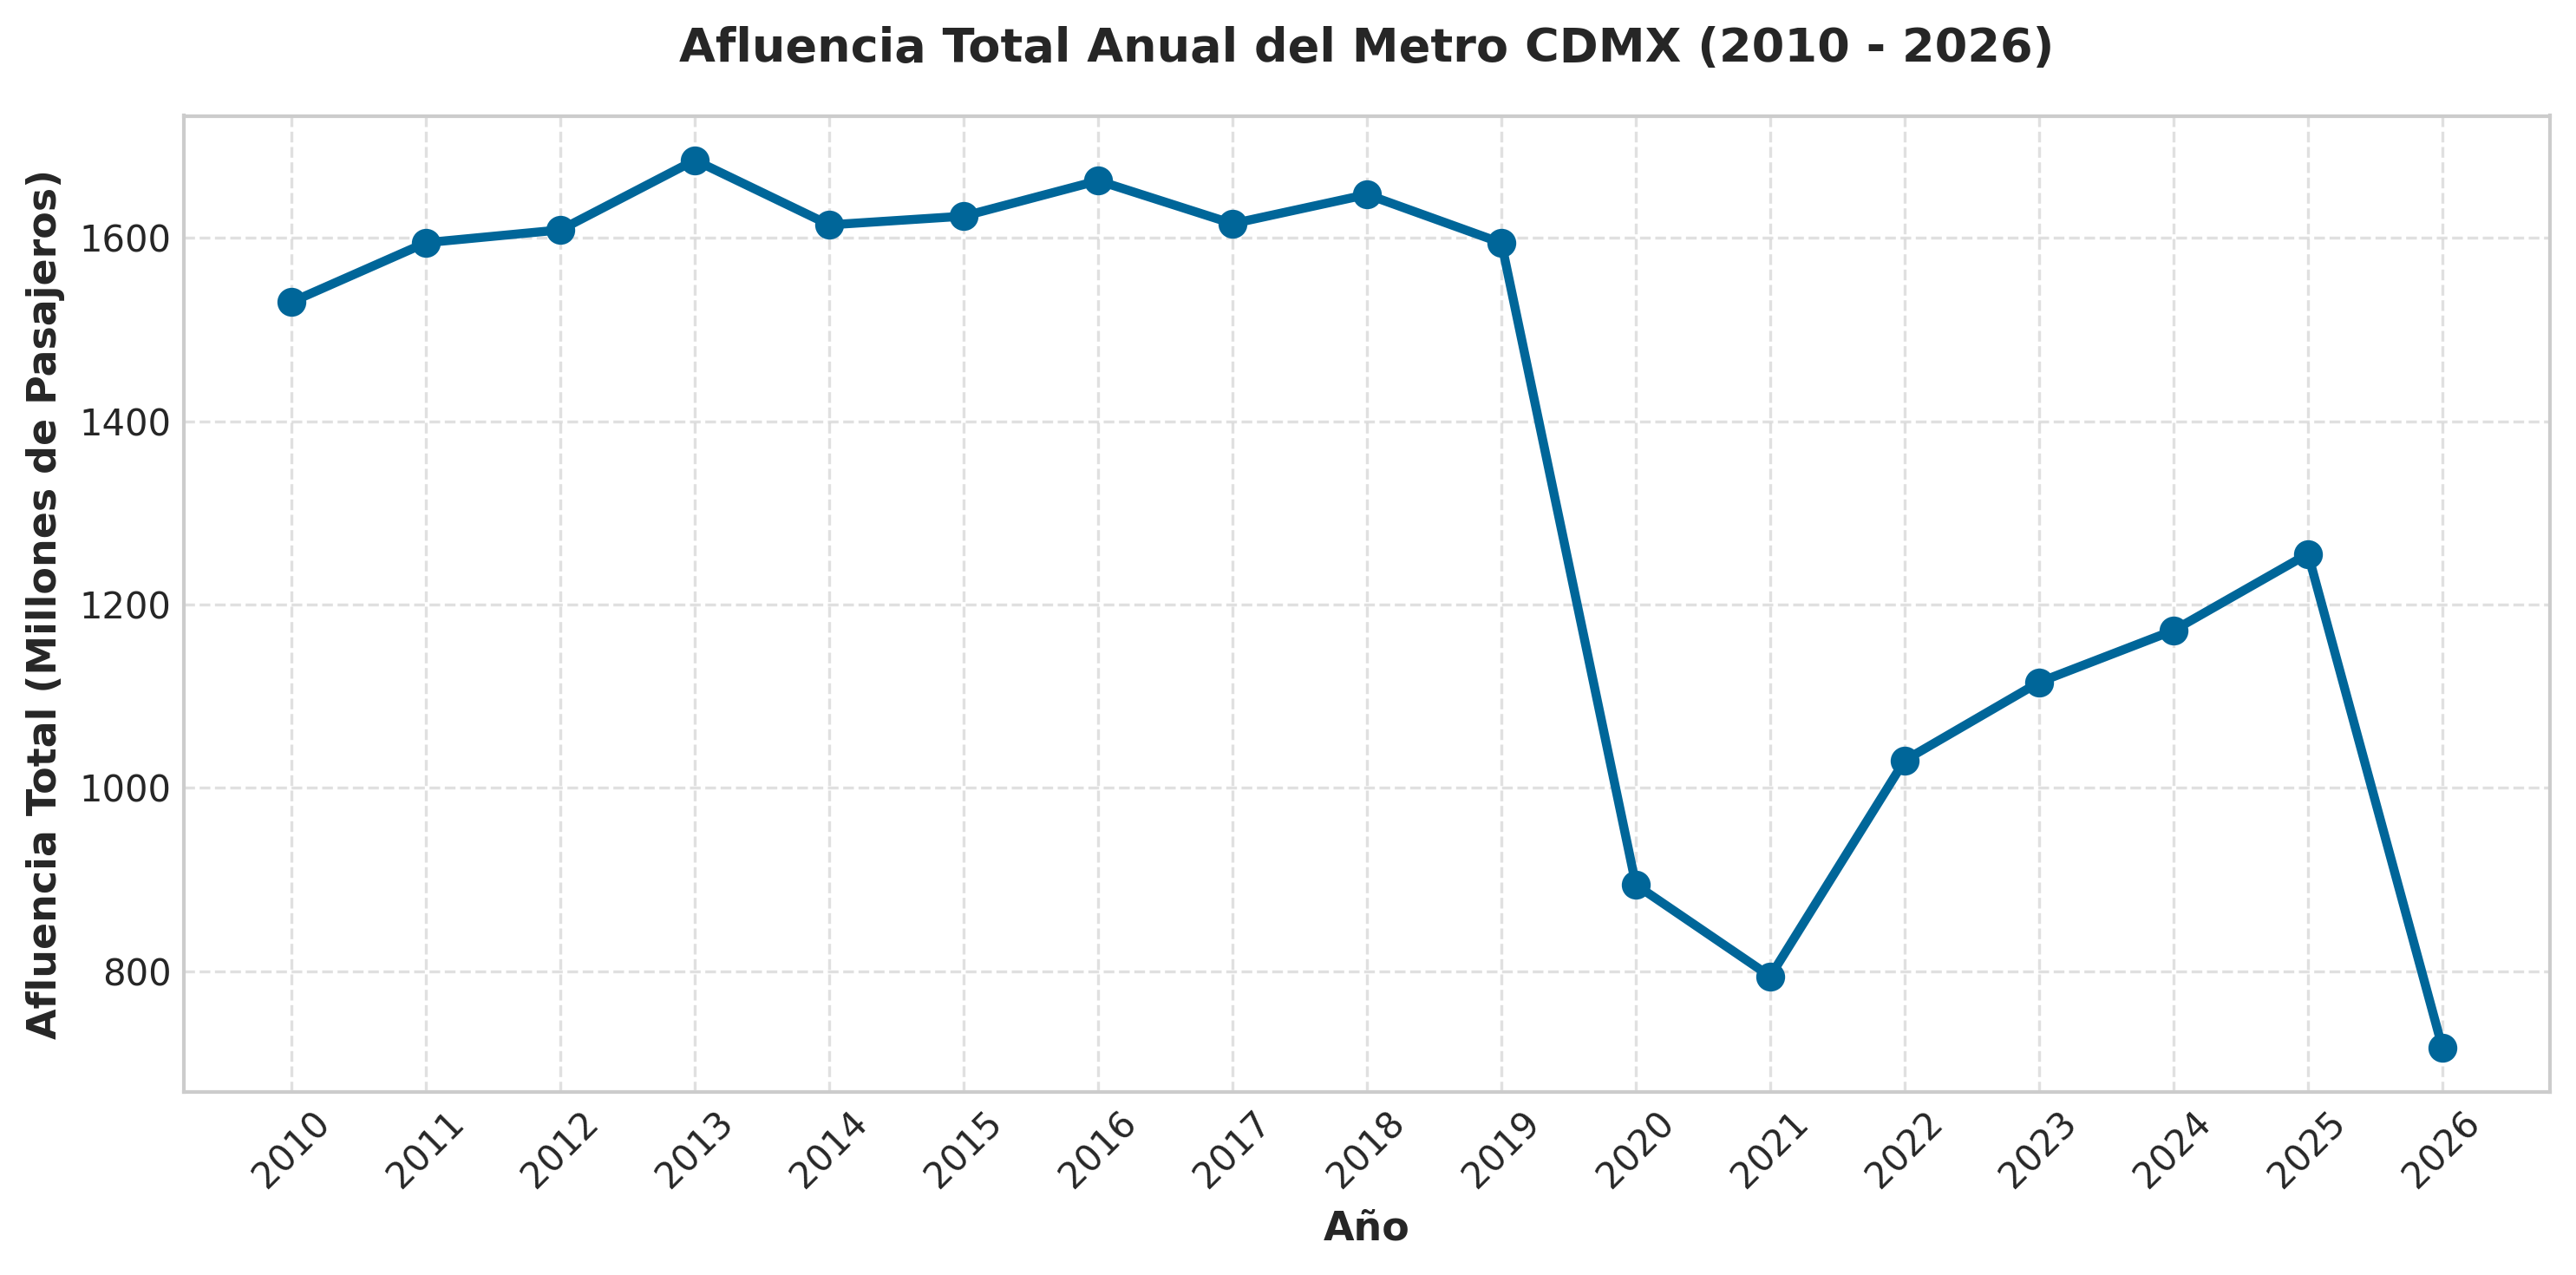

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Cargar datos con la función read_csv de pandas
# Definir el directorio donde se encuentra el dataset
mainpath = "drive/MyDrive/datasets"
filename = "Tren de la CDMX/0e8ffe58-28bb-4dde-afcd-e5f5b4de4ccb.csv"
fullpath = os.path.join(mainpath, filename)

# Lectura del archivo CSV
df = pd.read_csv(fullpath)

# Estilo gráfico profesional
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# FIGURA 2.2: Afluencia Total Anual del Metro CDMX
plt.figure(figsize=(10, 5), dpi=300)

# Agrupación por año y conversión a millones
df_yearly = df.groupby('anio')['afluencia'].sum() / 1e6

# Gráfico de línea con marcadores
plt.plot(
    df_yearly.index,
    df_yearly.values,
    marker='o',
    color='#006699',
    linewidth=2.5,
    markersize=7
)

plt.title('Afluencia Total Anual del Metro CDMX (2010 - 2026)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Año', fontsize=11, fontweight='bold')
plt.ylabel('Afluencia Total (Millones de Pasajeros)', fontsize=11, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(df_yearly.index, rotation=45)

plt.tight_layout()
plt.savefig('figura_2_2_grafico_preliminar_1.png', dpi=300)
plt.show()
plt.close()

Figura 2.3

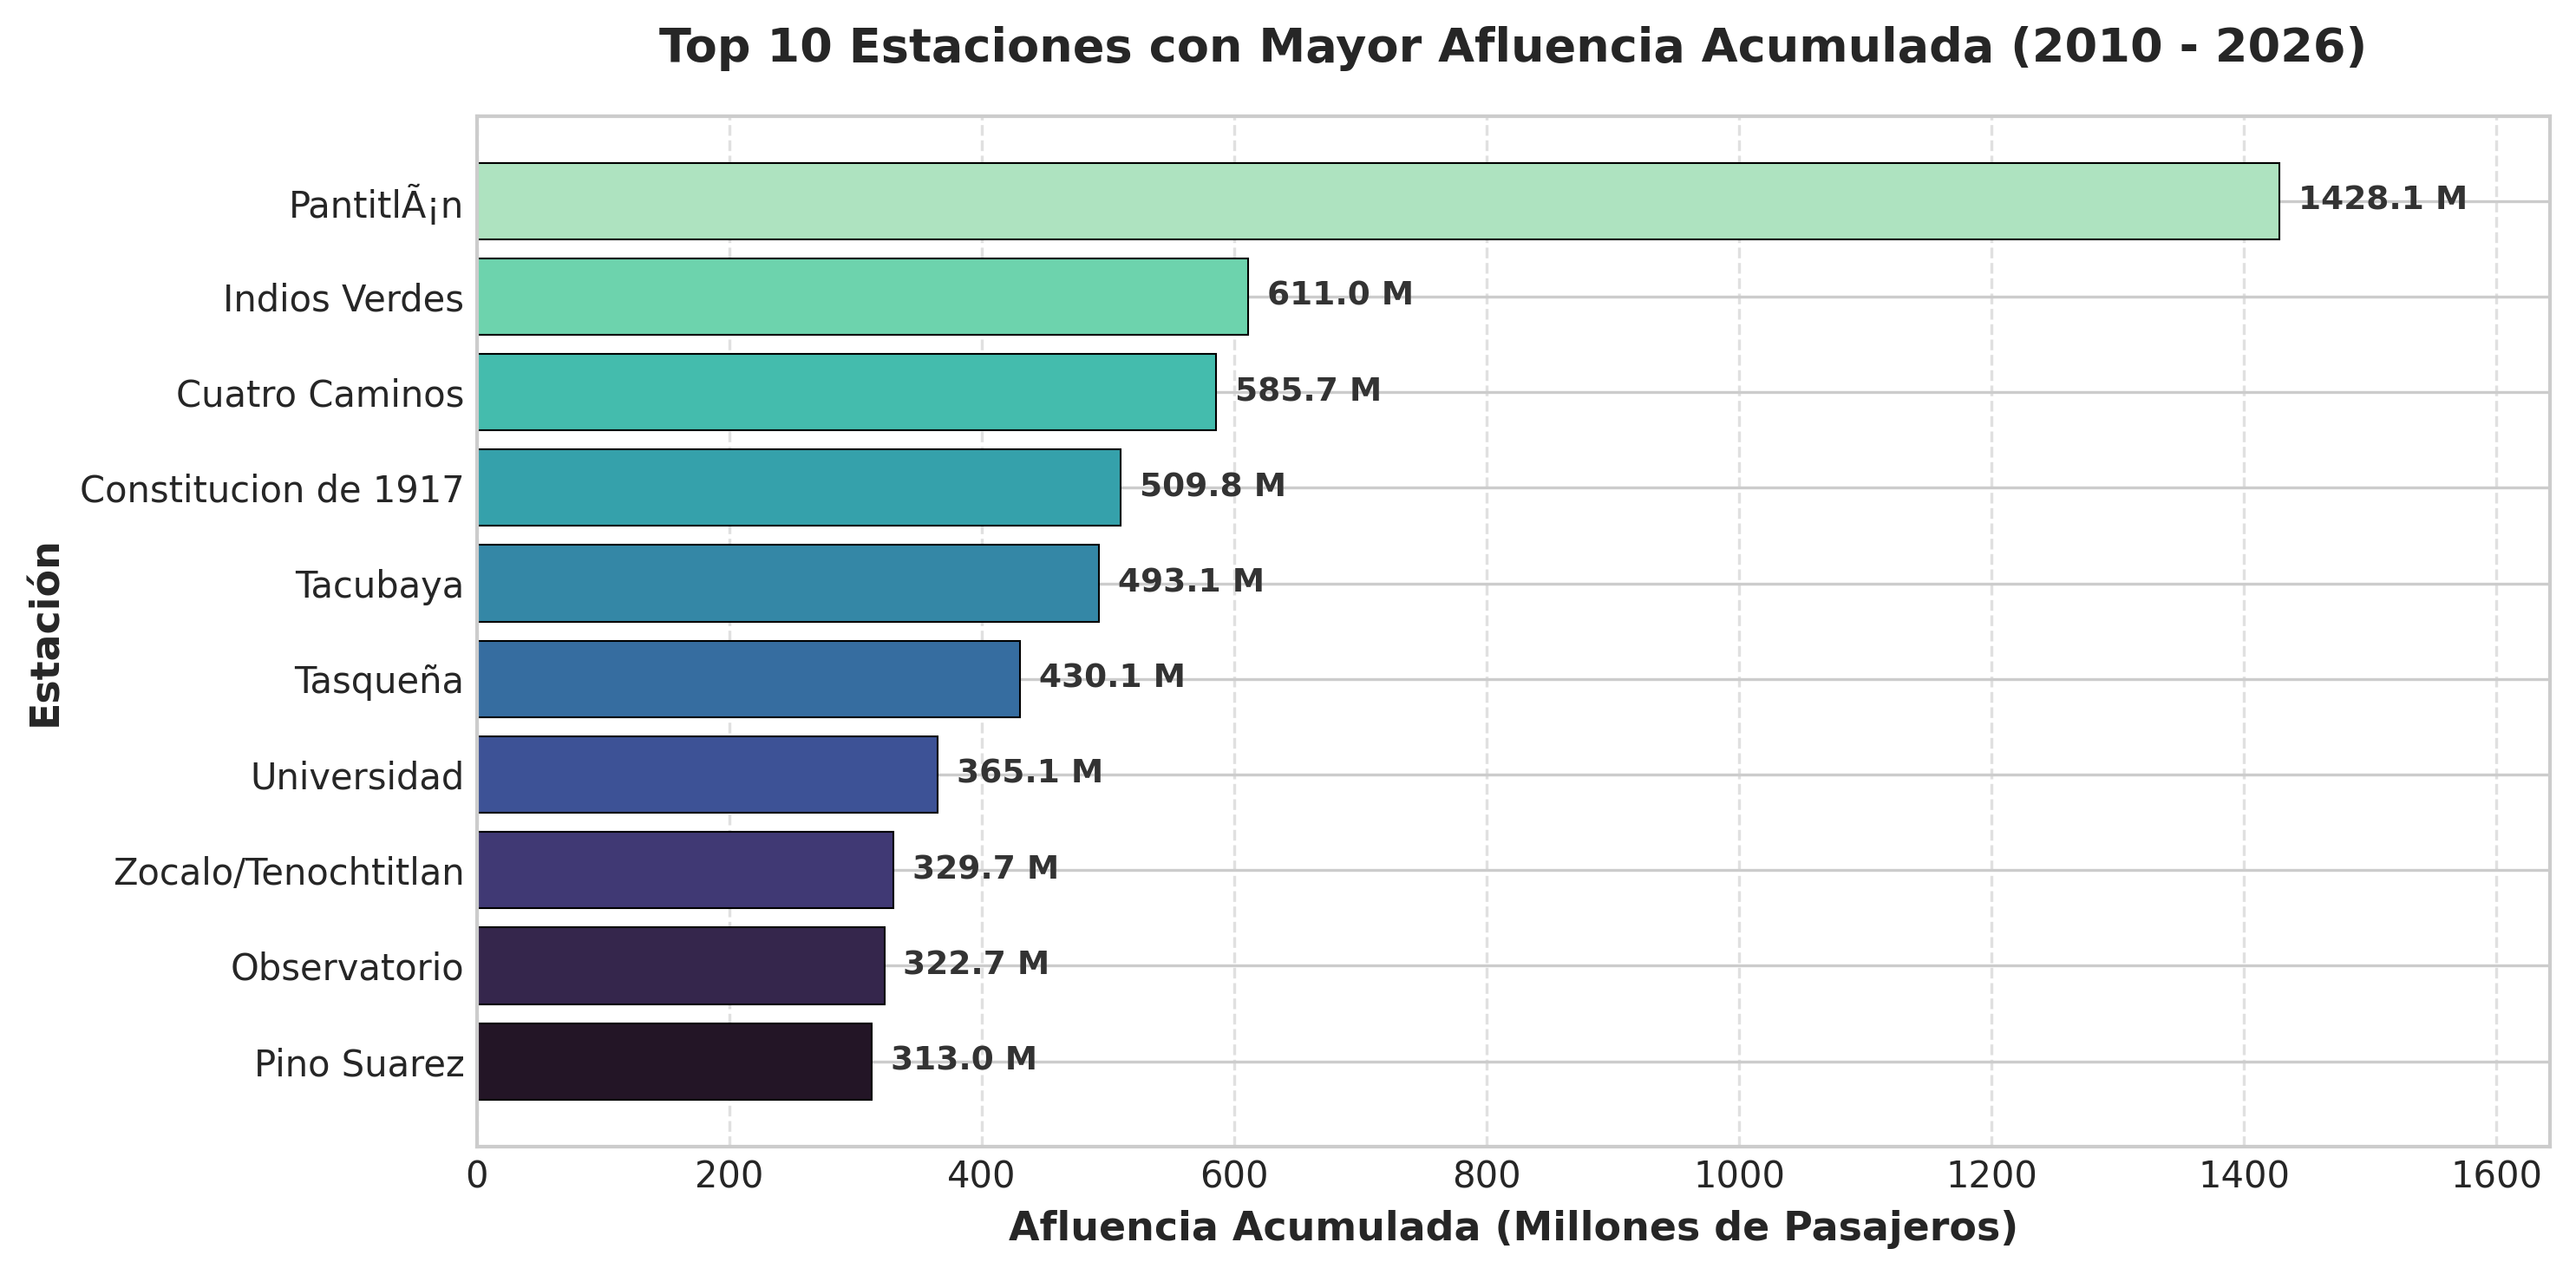

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Cargar datos con la función read_csv de pandas
# Definir el directorio donde se encuentra el dataset
mainpath = "drive/MyDrive/datasets"
filename = "Tren de la CDMX/0e8ffe58-28bb-4dde-afcd-e5f5b4de4ccb.csv"
fullpath = os.path.join(mainpath, filename)

# Lectura del archivo CSV
df = pd.read_csv(fullpath)

# Estilo gráfico profesional
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# FIGURA 2.3: Top 10 Estaciones con Mayor Afluencia
# Limpieza de caracteres especiales en nombres de estaciones
clean_map = {
    'PantitLÃ¡n': 'Pantitlan',
    'Pantitlán': 'Pantitlan',
    'Indios Verdes': 'Indios Verdes',
    'Cuatro Caminos': 'Cuatro Caminos',
    'ConstituciÃ³n de 1917': 'Constitucion de 1917',
    'Constitución de 1917': 'Constitucion de 1917',
    'Tacubaya': 'Tacubaya',
    'TasqueÃ±a': 'Tasqueña',
    'Tasqueña': 'Tasqueña',
    'Universidad': 'Universidad',
    'ZÃ³calo/Tenochtitlan': 'Zocalo/Tenochtitlan',
    'Zócalo/Tenochtitlan': 'Zocalo/Tenochtitlan',
    'Observatorio': 'Observatorio',
    'Pino SuÃ¡rez': 'Pino Suarez',
    'Pino Suarez': 'Pino Suarez'
}

df['estacion_clean'] = df['estacion'].replace(clean_map)

# Top 10 estaciones por afluencia acumulada en millones
top10 = df.groupby('estacion_clean')['afluencia'].sum().nlargest(10) / 1e6
top10 = top10.sort_values(ascending=True)

plt.figure(figsize=(10, 5), dpi=300)
colors = sns.color_palette("mako", n_colors=10)

# Gráfico de barras horizontales
bars = plt.barh(top10.index, top10.values, color=colors, edgecolor='black', linewidth=0.5)

plt.title('Top 10 Estaciones con Mayor Afluencia Acumulada (2010 - 2026)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Afluencia Acumulada (Millones de Pasajeros)', fontsize=11, fontweight='bold')
plt.ylabel('Estación', fontsize=11, fontweight='bold')
plt.grid(True, axis='x', linestyle='--', alpha=0.6)

# Etiquetas numéricas al final de cada barra
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 15,
        bar.get_y() + bar.get_height()/2,
        f'{width:.1f} M',
        va='center',
        ha='left',
        fontsize=9,
        fontweight='bold',
        color='#333333'
    )

plt.xlim(0, max(top10.values) * 1.15)
plt.tight_layout()
plt.savefig('figura_2_3_grafico_preliminar_2.png', dpi=300)
plt.show()
plt.close()